In [1]:
# ==========================================
# E-COMMERCE CUSTOMER SEGMENTATION
# K-Means + DBSCAN + PCA + t-SNE
# ==========================================

import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv('OnlineRetail.csv', encoding='latin1')

Saving OnlineRetail.csv to OnlineRetail.csv


In [4]:
# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Dataset information
print("\nDataset Information:")
print(df.info())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Number of unique customers
print(
    "\nUnique Customers:",
    df["CustomerID"].nunique()
)

# Number of unique invoices
print(
    "Unique Invoices:",
    df["InvoiceNo"].nunique()
)

# Number of unique products
print(
    "Unique Products:",
    df["StockCode"].nunique()
)

# Countries
if "Country" in df.columns:
    print(
        "Countries:",
        df["Country"].nunique()
    )

Rows: 541909
Columns: 8

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
None

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,1713.600303,12346.0,13953.0,15152.0,16791.0,18287.0
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Unique Customers: 4372
Unique Invoices: 25900
Unique Products: 4070
Countries: 38


In [5]:
# Keep a copy of original dataset
data = df.copy()

original_rows = len(data)

# Convert columns to appropriate data types
data["InvoiceNo"] = (
    data["InvoiceNo"]
    .astype("string")
    .str.strip()
)

data["InvoiceDate"] = pd.to_datetime(
    data["InvoiceDate"],
    errors="coerce",
    dayfirst=True
)

data["CustomerID"] = pd.to_numeric(
    data["CustomerID"],
    errors="coerce"
)

data["Quantity"] = pd.to_numeric(
    data["Quantity"],
    errors="coerce"
)

data["UnitPrice"] = pd.to_numeric(
    data["UnitPrice"],
    errors="coerce"
)

# Remove missing essential values
data.dropna(
    subset=[
        "InvoiceNo",
        "InvoiceDate",
        "CustomerID",
        "Quantity",
        "UnitPrice"
    ],
    inplace=True
)

# Remove cancelled invoices
data = data[
    ~data["InvoiceNo"].str.upper().str.startswith("C")
]

# Remove invalid quantities and prices
data = data[
    (data["Quantity"] > 0) &
    (data["UnitPrice"] > 0)
]

# Convert customer IDs to integer strings
data["CustomerID"] = (
    data["CustomerID"]
    .astype("int64")
    .astype(str)
)

# Calculate transaction revenue
data["Revenue"] = (
    data["Quantity"] *
    data["UnitPrice"]
)

data.reset_index(drop=True, inplace=True)

print("Original rows:", original_rows)
print("Cleaned rows:", len(data))
print("Removed rows:", original_rows - len(data))

print("\nCleaned dataset:")
display(data.head())

print("\nRemaining missing values:")
print(data.isnull().sum())

print("\nTotal revenue:", data["Revenue"].sum())

# Save cleaned data
data.to_csv(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\cleaned_retail_data.csv",
    index=False
)

Original rows: 541909
Cleaned rows: 168631
Removed rows: 373278

Cleaned dataset:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,20.34



Remaining missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64

Total revenue: 3875487.99


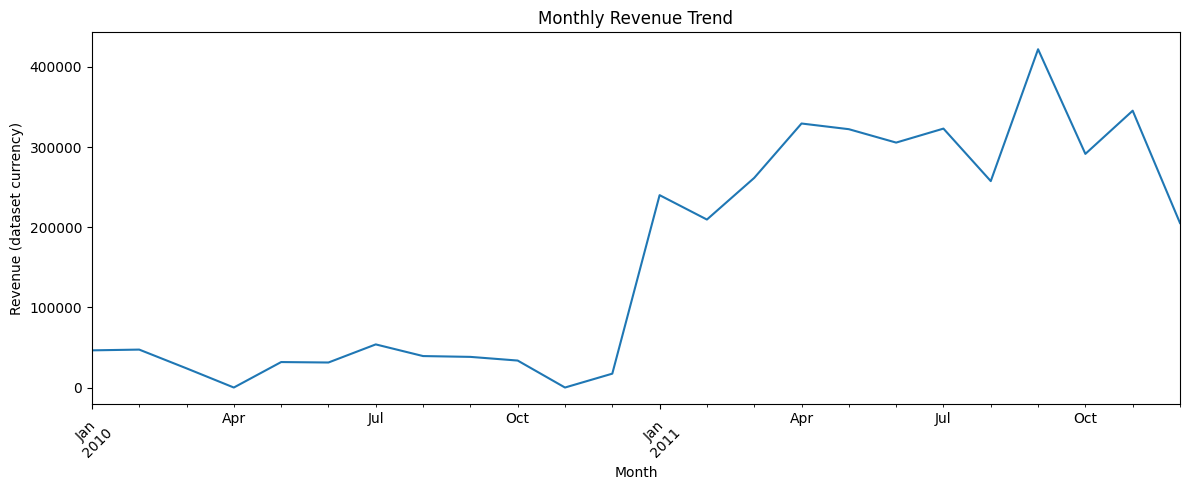

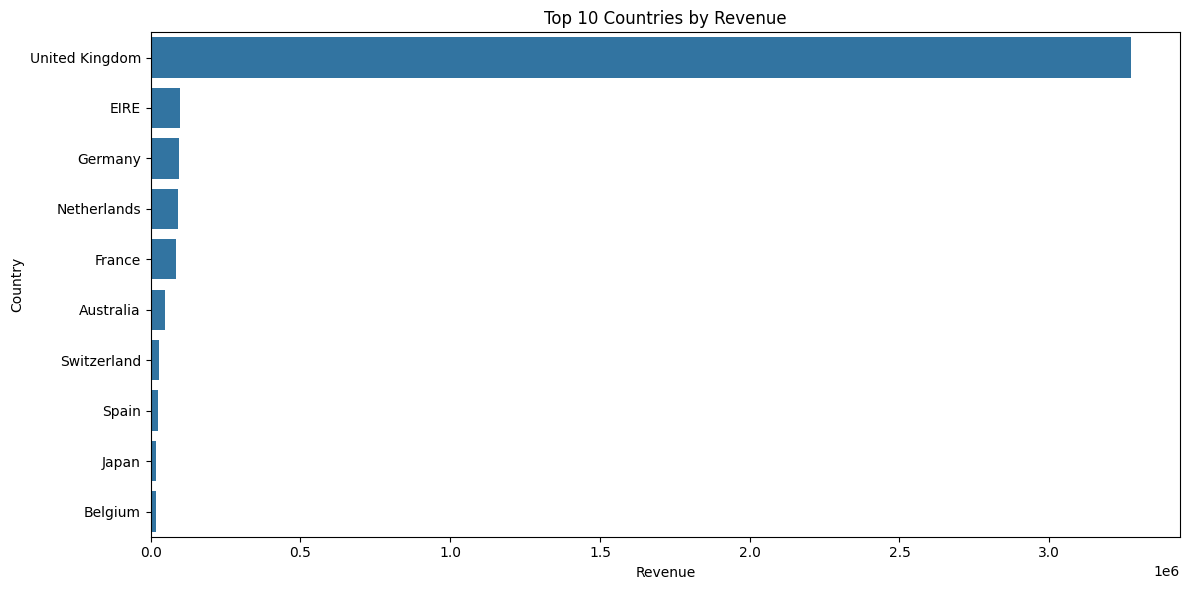

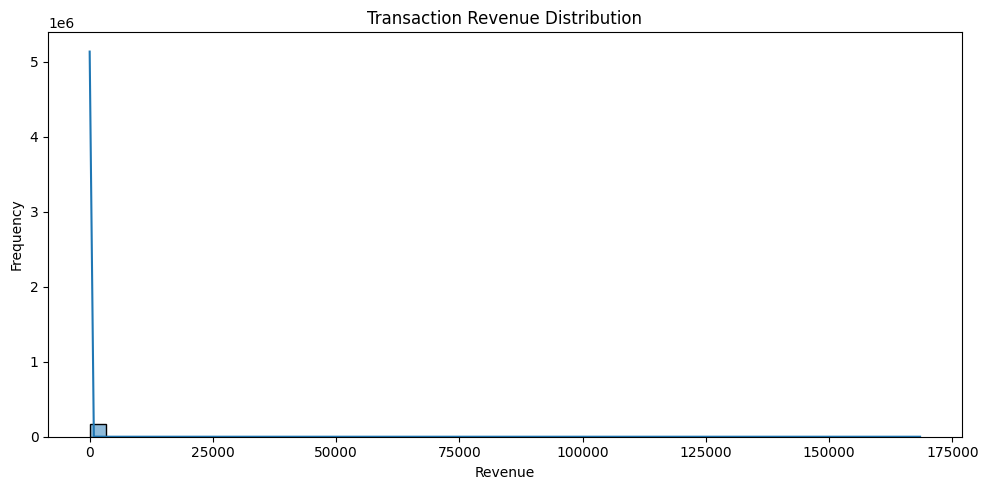

In [6]:
# Revenue by month
monthly_revenue = (
    data.set_index("InvoiceDate")
    .resample("ME")["Revenue"]
    .sum()
)

plt.figure(figsize=(12, 5))

monthly_revenue.plot()

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (dataset currency)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\monthly_revenue.png",
    dpi=300
)
plt.show()


# Top 10 countries by revenue
country_revenue = (
    data.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=country_revenue.values,
    y=country_revenue.index
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.tight_layout()
plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\top_countries.png",
    dpi=300
)
plt.show()


# Transaction revenue distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data["Revenue"],
    bins=50,
    kde=True
)

plt.title("Transaction Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\revenue_distribution.png",
    dpi=300
)
plt.show()

In [7]:
# Reference date:
# One day after the latest transaction in the dataset

reference_date = (
    data["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

# Calculate RFM metrics
rfm = data.groupby("CustomerID").agg(
    Recency=(
        "InvoiceDate",
        lambda x: (
            reference_date - x.max().normalize()
        ).days
    ),

    Frequency=(
        "InvoiceNo",
        "nunique"
    ),

    Monetary=(
        "Revenue",
        "sum"
    )
)

rfm = rfm.reset_index()

# Remove any invalid RFM rows
rfm = rfm[
    (rfm["Recency"] >= 0) &
    (rfm["Frequency"] > 0) &
    (rfm["Monetary"] > 0)
].copy()

print("RFM dataset generated!")

print("\nRFM Dataset Shape:")
print(rfm.shape)

print("\nFirst five customers:")
display(rfm.head())

print("\nRFM Statistical Summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

# Save RFM data
rfm.to_csv(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\rfm_dataset.csv",
    index=False
)

RFM dataset generated!

RFM Dataset Shape:
(2997, 4)

First five customers:


,CustomerID,Recency,Frequency,Monetary
0,12347,96,5,2540.29
1,12348,221,1,367.00
2,12350,312,1,334.40
3,12352,275,3,1296.38
4,12355,97,1,459.40



RFM Statistical Summary:


,Recency,Frequency,Monetary
count,2997.000000,2997.000000,2997.000000
mean,155.419086,2.656323,1293.122452
std,140.146976,4.008919,5274.262340
min,1.000000,1.000000,5.900000
25%,40.000000,1.000000,248.100000
50%,125.000000,2.000000,469.480000
75%,219.000000,3.000000,1068.190000
max,698.000000,106.000000,168469.600000


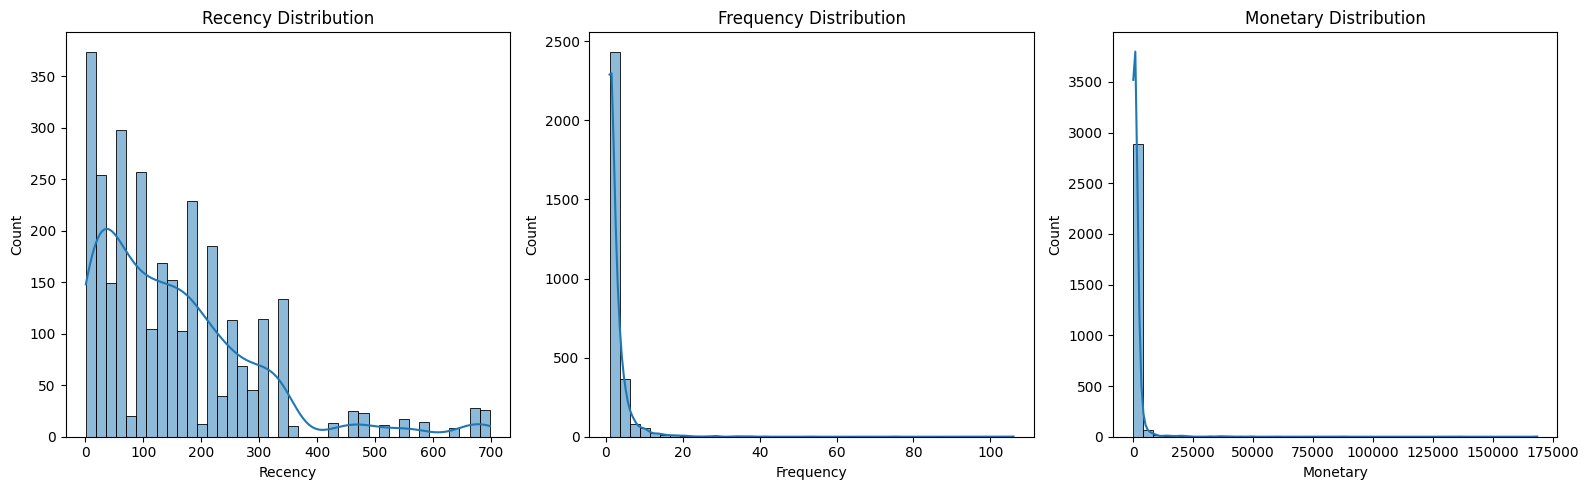

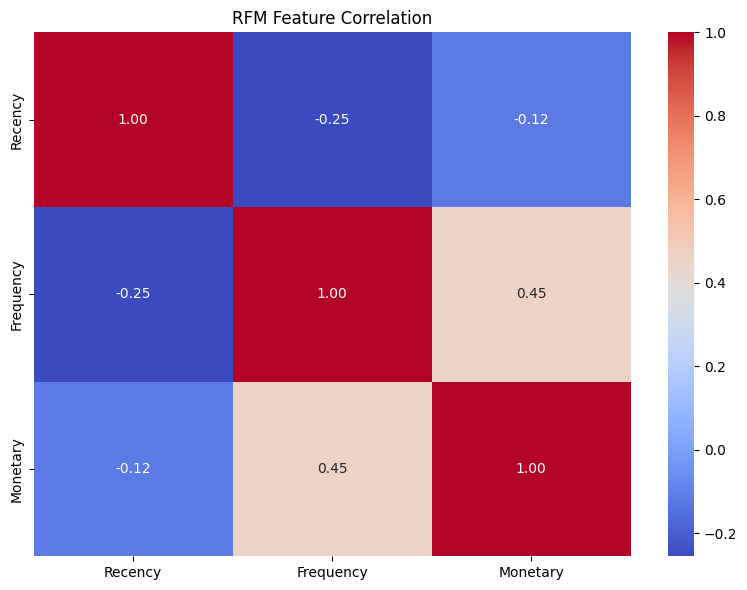

In [8]:
rfm_features = [
    "Recency",
    "Frequency",
    "Monetary"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for ax, feature in zip(axes, rfm_features):

    sns.histplot(
        rfm[feature],
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"{feature} Distribution")

plt.tight_layout()

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\rfm_distributions.png",
    dpi=300
)

plt.show()


# RFM correlation matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    rfm[rfm_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("RFM Feature Correlation")

plt.tight_layout()

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\rfm_correlation.png",
    dpi=300
)

plt.show()

In [9]:
# Apply logarithmic transformation
rfm_log = np.log1p(
    rfm[rfm_features]
)

# Feature scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(rfm_log)

print("Log transformation completed.")
print("Feature scaling completed.")

print("\nScaled feature matrix shape:")
print(X_scaled.shape)

print("\nFirst five scaled records:")
print(X_scaled[:5])

Log transformation completed.
Feature scaling completed.

Scaled feature matrix shape:
(2997, 3)

First five scaled records:
[[ 0.07727163  1.30702042  1.36642512]
 [ 0.68896168 -0.77418837 -0.2946265 ]
 [ 0.94275376 -0.77418837 -0.37436263]
 [ 0.84981275  0.53890818  0.78849159]
 [ 0.08484899 -0.77418837 -0.10206416]]


Explained Variance Ratio:
[0.68267359 0.23124736 0.08607905]

Cumulative Explained Variance: [0.68267359 0.91392095 1.        ]


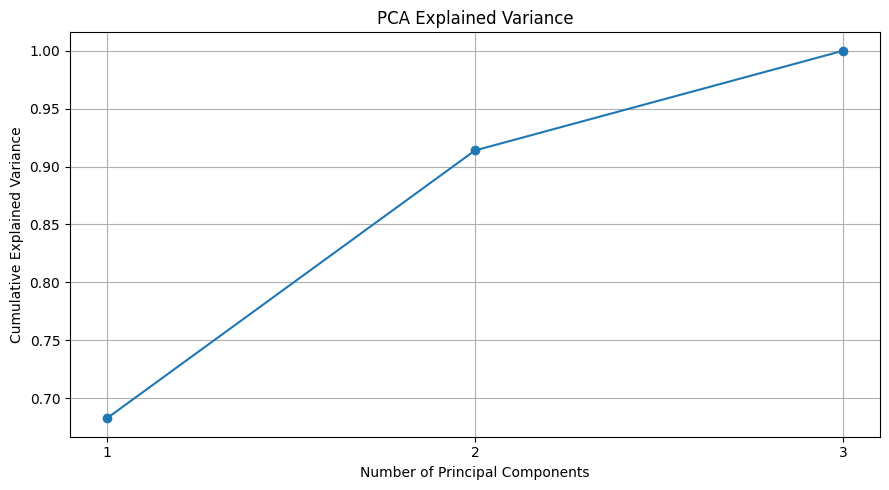


PCA Output Shape:
(2997, 2)
Variance retained by two components: 0.9139209524571655


In [10]:
# Fit PCA on the scaled RFM features
pca_full = PCA(
    random_state=42
)

pca_full.fit(X_scaled)

# Explained variance
explained_variance = (
    pca_full.explained_variance_ratio_
)

print("Explained Variance Ratio:")
print(explained_variance)

print(
    "\nCumulative Explained Variance:",
    explained_variance.cumsum()
)

# Plot explained variance
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance.cumsum(),
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("PCA Explained Variance")

plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\pca_variance.png",
    dpi=300
)

plt.show()


# Reduce data to two dimensions
pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_scaled)

print("\nPCA Output Shape:")
print(X_pca.shape)

print(
    "Variance retained by two components:",
    pca.explained_variance_ratio_.sum()
)

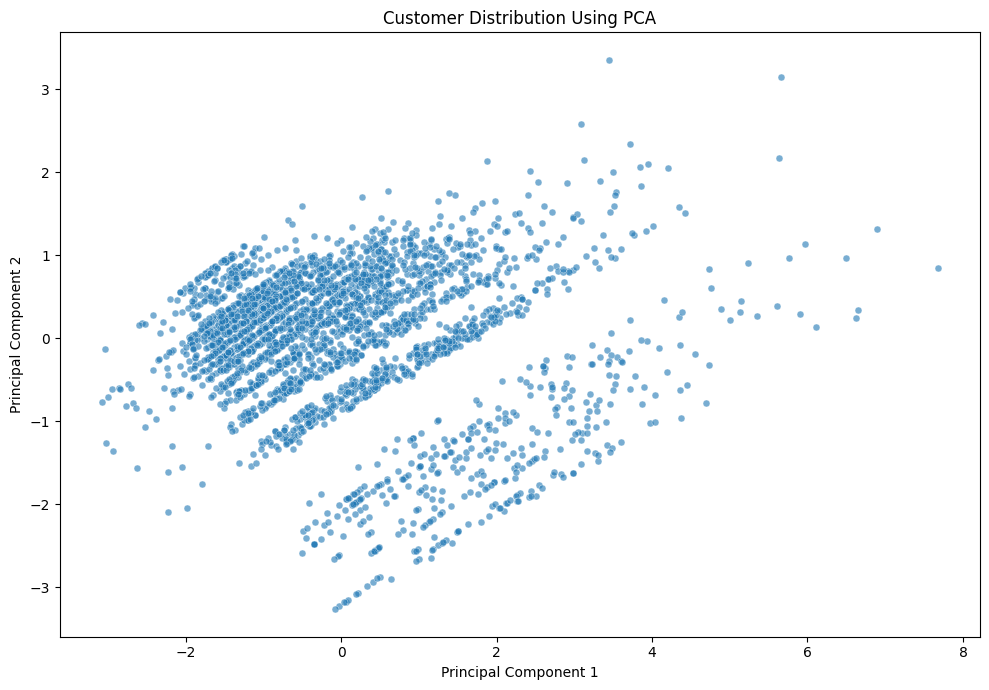

In [11]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    s=25,
    alpha=0.6
)

plt.title("Customer Distribution Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.tight_layout()

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\pca_visualization.png",
    dpi=300
)

plt.show()

,K,Inertia,Silhouette Score
0,2,4975.260037,0.439279
1,3,3899.655338,0.344483
2,4,2906.021523,0.385249
3,5,2472.636176,0.299363
4,6,2182.222438,0.308780
5,7,1942.218983,0.297663
6,8,1716.977083,0.305630
7,9,1593.906253,0.299954


Best K based on tested silhouette scores: 2


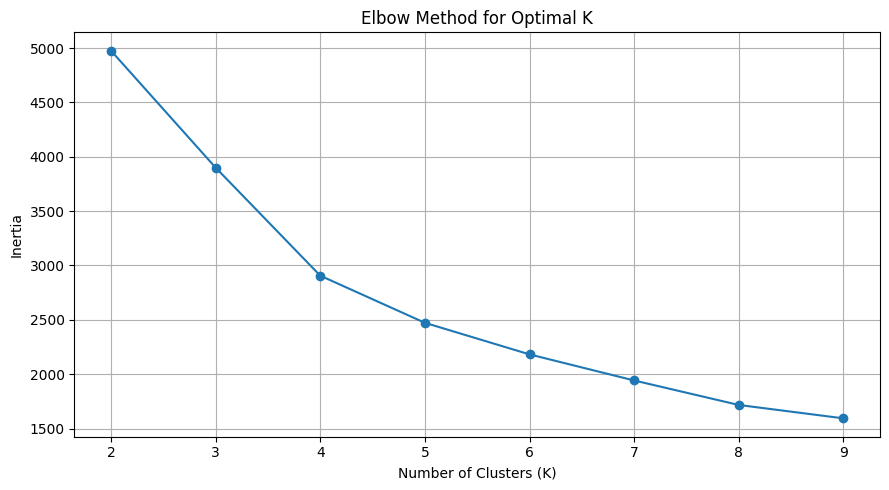

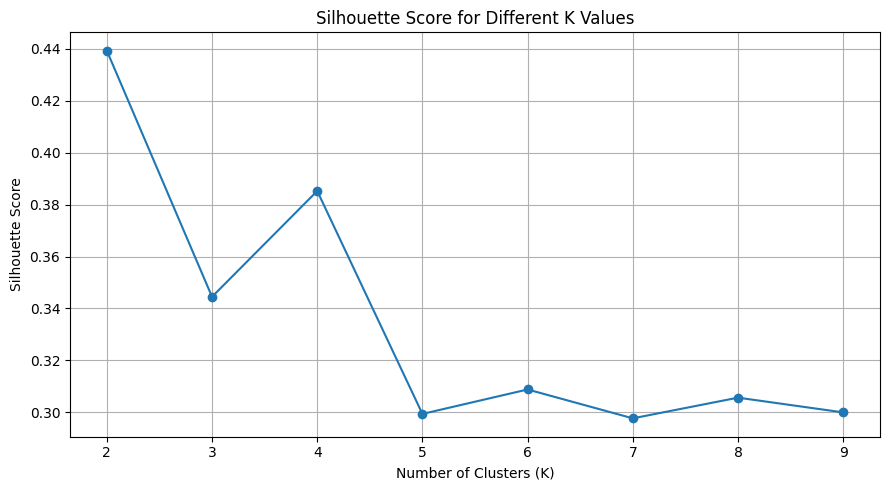

In [12]:
# Test different cluster counts
k_values = range(2, 10)

inertia_values = []
silhouette_values = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(3000, len(X_scaled)),
        random_state=42
    )

    silhouette_values.append(score)

# Display scores
results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(results)

# Select K with the highest tested silhouette score
best_k = int(
    results.loc[
        results["Silhouette Score"].idxmax(),
        "K"
    ]
)

print("Best K based on tested silhouette scores:", best_k)


# Plot elbow curve
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.grid(True)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\elbow_method.png",
    dpi=300
)

plt.show()


# Plot silhouette scores
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.grid(True)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\silhouette_scores.png",
    dpi=300
)

plt.show()

K-Means clustering completed!

Customer count in each cluster:
KMeansCluster
0     929
1    2068
Name: count, dtype: int64


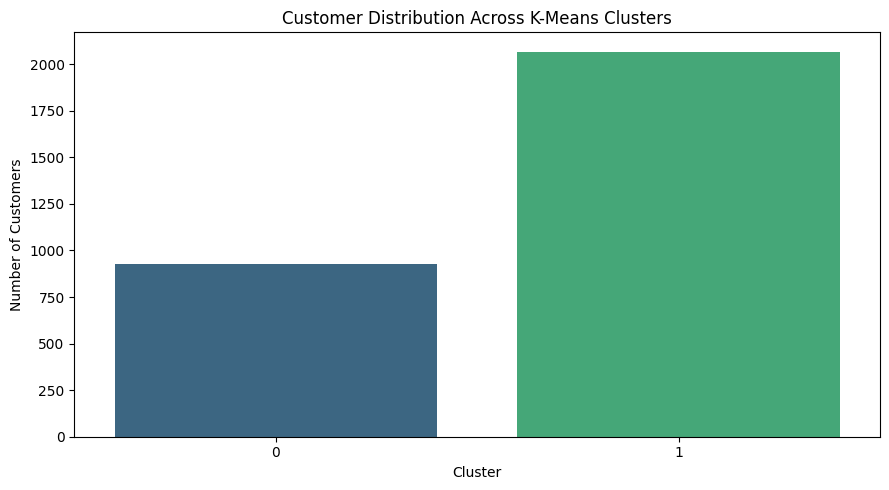

In [13]:
# Train final K-Means model
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

kmeans_labels = kmeans.fit_predict(X_scaled)

# Store cluster labels
rfm["KMeansCluster"] = kmeans_labels

print("K-Means clustering completed!")

print("\nCustomer count in each cluster:")

print(
    rfm["KMeansCluster"]
    .value_counts()
    .sort_index()
)

# Save cluster counts chart
plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm,
    x="KMeansCluster",
    hue="KMeansCluster",
    palette="viridis",
    legend=False
)

plt.title("Customer Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\kmeans_cluster_counts.png",
    dpi=300
)

plt.show()

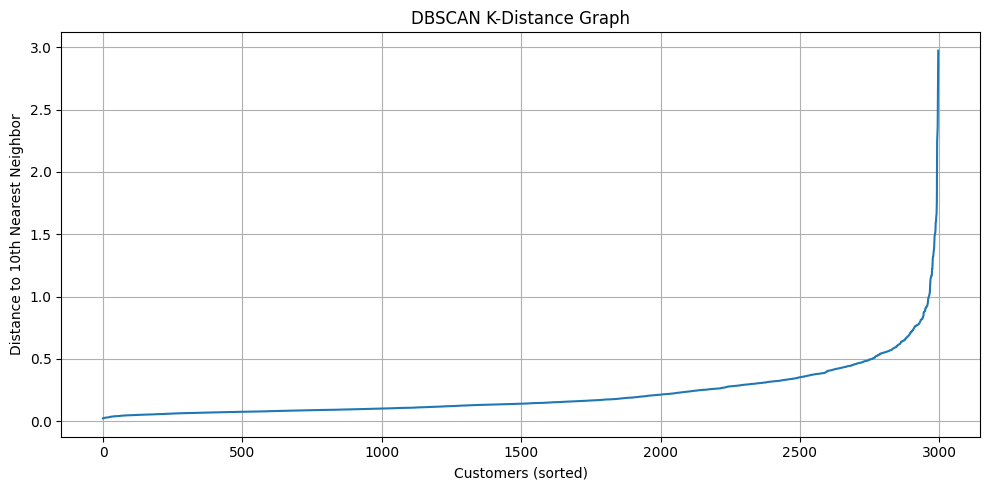

In [14]:
# DBSCAN parameters
MIN_SAMPLES = 10

# Calculate nearest-neighbour distances
neighbors = NearestNeighbors(
    n_neighbors=MIN_SAMPLES
)

neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(
    X_scaled
)

# Sort distances
k_distances = np.sort(
    distances[:, -1]
)

# Plot k-distance graph
plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Customers (sorted)")
plt.ylabel("Distance to 10th Nearest Neighbor")

plt.title("DBSCAN K-Distance Graph")
plt.grid(True)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\dbscan_k_distance.png",
    dpi=300
)

plt.show()

In [15]:
# Starting epsilon value.
# Inspect the k-distance graph and change this value
# if necessary.

DBSCAN_EPS = 0.8

dbscan = DBSCAN(
    eps=DBSCAN_EPS,
    min_samples=MIN_SAMPLES
)

dbscan_labels = dbscan.fit_predict(
    X_scaled
)

# Store labels
rfm["DBSCANCluster"] = dbscan_labels

# Cluster information
unique_labels = np.unique(dbscan_labels)

number_of_clusters = len(
    unique_labels[unique_labels != -1]
)

noise_points = np.sum(
    dbscan_labels == -1
)

noise_percentage = (
    noise_points / len(dbscan_labels)
) * 100

print("DBSCAN clustering completed!")

print(
    "Number of clusters:",
    number_of_clusters
)

print(
    "Number of noise points:",
    noise_points
)

print(
    "Noise percentage:",
    round(noise_percentage, 2),
    "%"
)

print("\nCluster distribution:")

print(
    pd.Series(dbscan_labels)
    .value_counts()
    .sort_index()
)

DBSCAN clustering completed!
Number of clusters: 1
Number of noise points: 29
Noise percentage: 0.97 %

Cluster distribution:
-1      29
 0    2968
Name: count, dtype: int64


In [16]:
# Starting epsilon value.
# Inspect the k-distance graph and change this value
# if necessary.

DBSCAN_EPS = 0.8

dbscan = DBSCAN(
    eps=DBSCAN_EPS,
    min_samples=MIN_SAMPLES
)

dbscan_labels = dbscan.fit_predict(
    X_scaled
)

# Store labels
rfm["DBSCANCluster"] = dbscan_labels

# Cluster information
unique_labels = np.unique(dbscan_labels)

number_of_clusters = len(
    unique_labels[unique_labels != -1]
)

noise_points = np.sum(
    dbscan_labels == -1
)

noise_percentage = (
    noise_points / len(dbscan_labels)
) * 100

print("DBSCAN clustering completed!")

print(
    "Number of clusters:",
    number_of_clusters
)

print(
    "Number of noise points:",
    noise_points
)

print(
    "Noise percentage:",
    round(noise_percentage, 2),
    "%"
)

print("\nCluster distribution:")

print(
    pd.Series(dbscan_labels)
    .value_counts()
    .sort_index()
)

DBSCAN clustering completed!
Number of clusters: 1
Number of noise points: 29
Noise percentage: 0.97 %

Cluster distribution:
-1      29
 0    2968
Name: count, dtype: int64


In [17]:
# K-Means evaluation
kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels,
    sample_size=min(3000, len(X_scaled)),
    random_state=42
)

kmeans_db_index = davies_bouldin_score(
    X_scaled,
    kmeans_labels
)

print("========== K-MEANS EVALUATION ==========")

print(
    "Silhouette Score:",
    round(kmeans_silhouette, 4)
)

print(
    "Davies-Bouldin Index:",
    round(kmeans_db_index, 4)
)


# DBSCAN evaluation
non_noise_mask = dbscan_labels != -1

dbscan_non_noise_labels = dbscan_labels[
    non_noise_mask
]

distinct_dbscan_clusters = np.unique(
    dbscan_non_noise_labels
)

dbscan_silhouette = None
dbscan_db_index = None

# Calculate metrics only if at least two
# non-noise clusters exist.

if (
    len(distinct_dbscan_clusters) >= 2
    and non_noise_mask.sum() > len(distinct_dbscan_clusters)
):

    dbscan_silhouette = silhouette_score(
        X_scaled[non_noise_mask],
        dbscan_non_noise_labels,
        sample_size=min(
            3000,
            non_noise_mask.sum()
        ),
        random_state=42
    )

    dbscan_db_index = davies_bouldin_score(
        X_scaled[non_noise_mask],
        dbscan_non_noise_labels
    )

print("\n========== DBSCAN EVALUATION ==========")

print(
    "Number of Clusters:",
    number_of_clusters
)

print(
    "Noise Percentage:",
    round(noise_percentage, 2),
    "%"
)

print(
    "Silhouette Score:",
    (
        round(dbscan_silhouette, 4)
        if dbscan_silhouette is not None
        else "Not defined"
    )
)

print(
    "Davies-Bouldin Index:",
    (
        round(dbscan_db_index, 4)
        if dbscan_db_index is not None
        else "Not defined"
    )
)


# Save evaluation results
evaluation = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Clusters": best_k,
        "Silhouette Score": kmeans_silhouette,
        "Davies-Bouldin Index": kmeans_db_index,
        "Noise Percentage": 0
    },
    {
        "Algorithm": "DBSCAN",
        "Clusters": number_of_clusters,
        "Silhouette Score": dbscan_silhouette,
        "Davies-Bouldin Index": dbscan_db_index,
        "Noise Percentage": noise_percentage
    }
])

print("\nModel Comparison:")
display(evaluation)

evaluation.to_csv(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\model_evaluation.csv",
    index=False
)

========== K-MEANS EVALUATION ==========
Silhouette Score: 0.4393
Davies-Bouldin Index: 0.9715

========== DBSCAN EVALUATION ==========
Number of Clusters: 1
Noise Percentage: 0.97 %
Silhouette Score: Not defined
Davies-Bouldin Index: Not defined

Model Comparison:


,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index,Noise Percentage
0,K-Means,2,0.439279,0.971492,0.000000
1,DBSCAN,1,NaN,NaN,0.967634


In [18]:
# Calculate a valid perplexity for the dataset
perplexity = min(
    30,
    max(2, (len(X_scaled) - 1) // 3)
)

# Create t-SNE model
tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto",
    random_state=42,
    max_iter=1000
)

# Fit t-SNE
X_tsne = tsne.fit_transform(X_scaled)

# Create visualization dataframe
tsne_results = pd.DataFrame({
    "TSNE1": X_tsne[:, 0],
    "TSNE2": X_tsne[:, 1],
    "KMeansCluster": kmeans_labels.astype(str),
    "DBSCANCluster": dbscan_labels.astype(str)
})

print("t-SNE transformation completed!")

print("Output shape:", X_tsne.shape)

t-SNE transformation completed!
Output shape: (2997, 2)


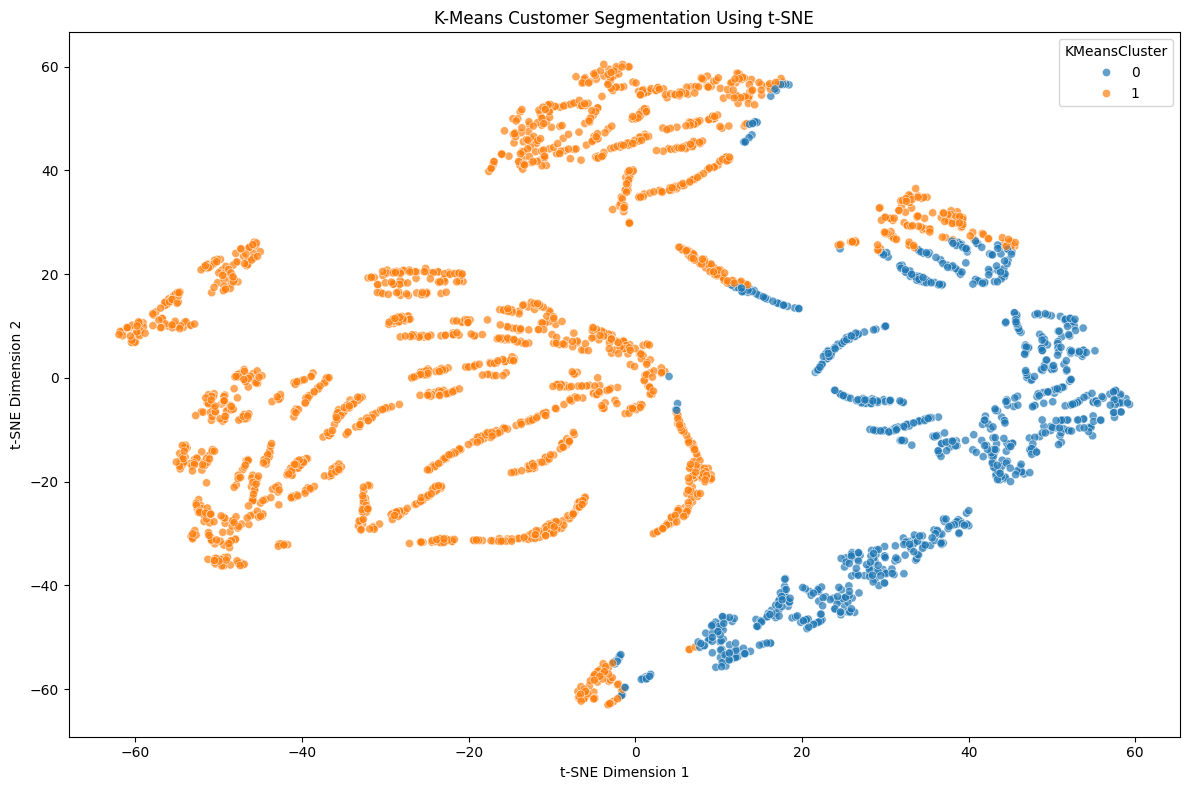

In [19]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=tsne_results,
    x="TSNE1",
    y="TSNE2",
    hue="KMeansCluster",
    palette="tab10",
    s=35,
    alpha=0.7
)

plt.title("K-Means Customer Segmentation Using t-SNE")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.tight_layout()

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\tsne_kmeans.png",
    dpi=300
)

plt.show()

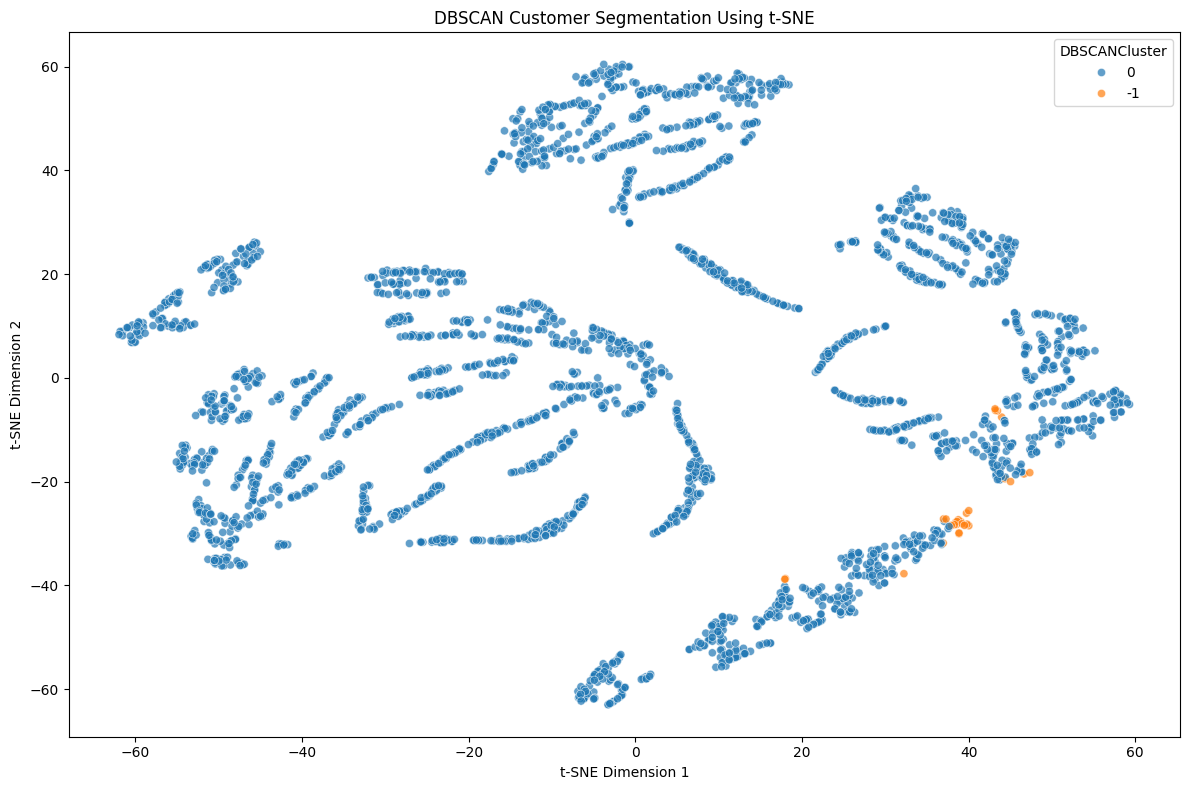

In [20]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=tsne_results,
    x="TSNE1",
    y="TSNE2",
    hue="DBSCANCluster",
    palette="tab10",
    s=35,
    alpha=0.7
)

plt.title("DBSCAN Customer Segmentation Using t-SNE")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.tight_layout()

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\tsne_dbscan.png",
    dpi=300
)

plt.show()

In [21]:
# Calculate global RFM thresholds
q25 = rfm[rfm_features].quantile(0.25)
q50 = rfm[rfm_features].quantile(0.50)
q75 = rfm[rfm_features].quantile(0.75)


# Define persona classification function
def assign_persona(row):

    recency = row["MedianRecency"]
    frequency = row["MedianFrequency"]
    monetary = row["MedianMonetary"]

    # Champions
    if (
        recency <= q25["Recency"] and
        frequency >= q75["Frequency"] and
        monetary >= q75["Monetary"]
    ):
        return "Champions"

    # High-value customers who may be at risk
    elif (
        recency >= q75["Recency"] and
        frequency >= q75["Frequency"] and
        monetary >= q50["Monetary"]
    ):
        return "At-Risk High-Value Customers"

    # Loyal customers
    elif (
        frequency >= q75["Frequency"] and
        recency <= q75["Recency"]
    ):
        return "Loyal Customers"

    # High monetary value but low frequency
    elif (
        monetary >= q75["Monetary"] and
        frequency <= q50["Frequency"]
    ):
        return "Big Spenders / Occasional Buyers"

    # Recently active customers
    elif (
        recency <= q25["Recency"] and
        frequency <= q50["Frequency"]
    ):
        return "Recent / New Customers"

    # Inactive customers
    elif (
        recency >= q75["Recency"] and
        frequency <= q50["Frequency"] and
        monetary <= q50["Monetary"]
    ):
        return "Hibernating Customers"

    else:
        return "Regular / Developing Customers"


# Marketing strategies
marketing_actions = {

    "Champions":
    "VIP rewards, exclusive offers and loyalty programs",

    "Loyal Customers":
    "Memberships, cross-selling and referral campaigns",

    "At-Risk High-Value Customers":
    "Personalized win-back campaigns and loyalty incentives",

    "Big Spenders / Occasional Buyers":
    "Premium product recommendations and product bundles",

    "Recent / New Customers":
    "Welcome discounts and second-purchase incentives",

    "Hibernating Customers":
    "Reactivation emails and limited-time discounts",

    "Regular / Developing Customers":
    "Personalized recommendations and promotional bundles",

    "Noise / Outlier Customers":
    "Investigate unusual behaviour before launching targeted campaigns"
}


# Profile generator
def create_cluster_profile(data, cluster_column):

    profile = (
        data.groupby(cluster_column)
        .agg(
            CustomerCount=("CustomerID", "nunique"),

            MedianRecency=("Recency", "median"),

            MedianFrequency=("Frequency", "median"),

            MedianMonetary=("Monetary", "median"),

            AverageMonetary=("Monetary", "mean")
        )
        .reset_index()
    )

    profile["Persona"] = profile.apply(
        lambda row: (
            "Noise / Outlier Customers"
            if (
                cluster_column == "DBSCANCluster"
                and row[cluster_column] == -1
            )
            else assign_persona(row)
        ),
        axis=1
    )

    profile["MarketingAction"] = (
        profile["Persona"].map(marketing_actions)
    )

    return profile


# Prepare profile dataset
rfm_profiles = rfm.copy()

# K-Means profiles
kmeans_profile = create_cluster_profile(
    rfm_profiles,
    "KMeansCluster"
)

# DBSCAN profiles
dbscan_profile = create_cluster_profile(
    rfm_profiles,
    "DBSCANCluster"
)

print("K-Means Customer Personas:")
display(kmeans_profile)

print("\nDBSCAN Customer Personas:")
display(dbscan_profile)

# Save profiles
kmeans_profile.to_csv(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\cluster_profiles.csv",
    index=False
)

dbscan_profile.to_csv(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\dbscan_cluster_profiles.csv",
    index=False
)

K-Means Customer Personas:


,KMeansCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,0,929,36.0,4.0,1482.510,3231.367018,Champions,"VIP rewards, exclusive offers and loyalty prog..."
1,1,2068,182.0,1.0,317.355,422.412007,Regular / Developing Customers,Personalized recommendations and promotional b...



DBSCAN Customer Personas:


,DBSCANCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,-1,29,6.0,24.0,27867.5,35733.395862,Noise / Outlier Customers,Investigate unusual behaviour before launching...
1,0,2968,126.0,2.0,464.9,956.610347,Regular / Developing Customers,Personalized recommendations and promotional b...


In [22]:
# Calculate global RFM thresholds
q25 = rfm[rfm_features].quantile(0.25)
q50 = rfm[rfm_features].quantile(0.50)
q75 = rfm[rfm_features].quantile(0.75)


# Define persona classification function
def assign_persona(row):

    recency = row["MedianRecency"]
    frequency = row["MedianFrequency"]
    monetary = row["MedianMonetary"]

    # Champions
    if (
        recency <= q25["Recency"] and
        frequency >= q75["Frequency"] and
        monetary >= q75["Monetary"]
    ):
        return "Champions"

    # High-value customers who may be at risk
    elif (
        recency >= q75["Recency"] and
        frequency >= q75["Frequency"] and
        monetary >= q50["Monetary"]
    ):
        return "At-Risk High-Value Customers"

    # Loyal customers
    elif (
        frequency >= q75["Frequency"] and
        recency <= q75["Recency"]
    ):
        return "Loyal Customers"

    # High monetary value but low frequency
    elif (
        monetary >= q75["Monetary"] and
        frequency <= q50["Frequency"]
    ):
        return "Big Spenders / Occasional Buyers"

    # Recently active customers
    elif (
        recency <= q25["Recency"] and
        frequency <= q50["Frequency"]
    ):
        return "Recent / New Customers"

    # Inactive customers
    elif (
        recency >= q75["Recency"] and
        frequency <= q50["Frequency"] and
        monetary <= q50["Monetary"]
    ):
        return "Hibernating Customers"

    else:
        return "Regular / Developing Customers"


# Marketing strategies
marketing_actions = {

    "Champions":
    "VIP rewards, exclusive offers and loyalty programs",

    "Loyal Customers":
    "Memberships, cross-selling and referral campaigns",

    "At-Risk High-Value Customers":
    "Personalized win-back campaigns and loyalty incentives",

    "Big Spenders / Occasional Buyers":
    "Premium product recommendations and product bundles",

    "Recent / New Customers":
    "Welcome discounts and second-purchase incentives",

    "Hibernating Customers":
    "Reactivation emails and limited-time discounts",

    "Regular / Developing Customers":
    "Personalized recommendations and promotional bundles",

    "Noise / Outlier Customers":
    "Investigate unusual behaviour before launching targeted campaigns"
}


# Profile generator
def create_cluster_profile(data, cluster_column):

    profile = (
        data.groupby(cluster_column)
        .agg(
            CustomerCount=("CustomerID", "nunique"),

            MedianRecency=("Recency", "median"),

            MedianFrequency=("Frequency", "median"),

            MedianMonetary=("Monetary", "median"),

            AverageMonetary=("Monetary", "mean")
        )
        .reset_index()
    )

    profile["Persona"] = profile.apply(
        lambda row: (
            "Noise / Outlier Customers"
            if (
                cluster_column == "DBSCANCluster"
                and row[cluster_column] == -1
            )
            else assign_persona(row)
        ),
        axis=1
    )

    profile["MarketingAction"] = (
        profile["Persona"].map(marketing_actions)
    )

    return profile


# Prepare profile dataset
rfm_profiles = rfm.copy()

# K-Means profiles
kmeans_profile = create_cluster_profile(
    rfm_profiles,
    "KMeansCluster"
)

# DBSCAN profiles
dbscan_profile = create_cluster_profile(
    rfm_profiles,
    "DBSCANCluster"
)

print("K-Means Customer Personas:")
display(kmeans_profile)

print("\nDBSCAN Customer Personas:")
display(dbscan_profile)

# Save profiles
kmeans_profile.to_csv(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\cluster_profiles.csv",
    index=False
)

dbscan_profile.to_csv(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\dbscan_cluster_profiles.csv",
    index=False
)

K-Means Customer Personas:


,KMeansCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,0,929,36.0,4.0,1482.510,3231.367018,Champions,"VIP rewards, exclusive offers and loyalty prog..."
1,1,2068,182.0,1.0,317.355,422.412007,Regular / Developing Customers,Personalized recommendations and promotional b...



DBSCAN Customer Personas:


,DBSCANCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,-1,29,6.0,24.0,27867.5,35733.395862,Noise / Outlier Customers,Investigate unusual behaviour before launching...
1,0,2968,126.0,2.0,464.9,956.610347,Regular / Developing Customers,Personalized recommendations and promotional b...


In [23]:
# Map K-Means cluster IDs to persona names
kmeans_persona_map = (
    kmeans_profile
    .set_index("KMeansCluster")["Persona"]
    .to_dict()
)

# Map DBSCAN cluster IDs to persona names
dbscan_persona_map = (
    dbscan_profile
    .set_index("DBSCANCluster")["Persona"]
    .to_dict()
)

# Add persona information
rfm["KMeansPersona"] = (
    rfm["KMeansCluster"]
    .map(kmeans_persona_map)
)

rfm["DBSCANPersona"] = (
    rfm["DBSCANCluster"]
    .map(dbscan_persona_map)
)

# Add marketing recommendations
rfm["MarketingRecommendation"] = (
    rfm["KMeansPersona"]
    .map(marketing_actions)
)

# Save final segmentation
rfm.to_csv(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results\customer_segments.csv",
    index=False
)

print("Final customer segmentation generated!")

display(rfm.head(10))

print("\nK-Means Persona Distribution:")

print(
    rfm["KMeansPersona"]
    .value_counts()
)

print("\nDBSCAN Persona Distribution:")

print(
    rfm["DBSCANPersona"]
    .value_counts()
)

Final customer segmentation generated!


,CustomerID,Recency,Frequency,Monetary,KMeansCluster,DBSCANCluster,KMeansPersona,DBSCANPersona,MarketingRecommendation
0,12347,96,5,2540.29,0,0,Champions,Regular / Developing Customers,"VIP rewards, exclusive offers and loyalty prog..."
1,12348,221,1,367.00,1,0,Regular / Developing Customers,Regular / Developing Customers,Personalized recommendations and promotional b...
2,12350,312,1,334.40,1,0,Regular / Developing Customers,Regular / Developing Customers,Personalized recommendations and promotional b...
3,12352,275,3,1296.38,1,0,Regular / Developing Customers,Regular / Developing Customers,Personalized recommendations and promotional b...
4,12355,97,1,459.40,1,0,Regular / Developing Customers,Regular / Developing Customers,Personalized recommendations and promotional b...
5,12356,129,1,481.46,1,0,Regular / Developing Customers,Regular / Developing Customers,Personalized recommendations and promotional b...
6,12357,183,1,6207.67,1,0,Regular / Developing Customers,Regular / Developing Customers,Personalized recommendations and promotional b...
7,12358,4,2,1168.06,0,0,Champions,Regular / Developing Customers,"VIP rewards, exclusive offers and loyalty prog..."
8,12359,10,3,3495.73,0,0,Champions,Regular / Developing Customers,"VIP rewards, exclusive offers and loyalty prog..."
9,12362,31,5,2135.79,0,0,Champions,Regular / Developing Customers,"VIP rewards, exclusive offers and loyalty prog..."



K-Means Persona Distribution:
KMeansPersona
Regular / Developing Customers    2068
Champions                          929
Name: count, dtype: int64

DBSCAN Persona Distribution:
DBSCANPersona
Regular / Developing Customers    2968
Noise / Outlier Customers           29
Name: count, dtype: int64


In [24]:
print("=" * 55)
print("E-COMMERCE CUSTOMER SEGMENTATION - FINAL SUMMARY")
print("=" * 55)

print("\nDataset Information")

print("Original transactions:", original_rows)
print("Cleaned transactions:", len(data))
print("Total customers:", len(rfm))

print("\nRFM Metrics")

print("Recency calculated successfully")
print("Frequency calculated successfully")
print("Monetary calculated successfully")

print("\nK-Means Results")

print("Optimal tested K:", best_k)
print(
    "Silhouette Score:",
    round(kmeans_silhouette, 4)
)

print("\nDBSCAN Results")

print("Clusters:", number_of_clusters)
print("Noise Percentage:", round(noise_percentage, 2), "%")

print("\nK-Means Customer Personas")

display(kmeans_profile)

print("\nDBSCAN Customer Personas")

display(dbscan_profile)

print("\nSaved project files in:",
      r"C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results")

print("\nPROJECT COMPLETED SUCCESSFULLY!")

E-COMMERCE CUSTOMER SEGMENTATION - FINAL SUMMARY

Dataset Information
Original transactions: 541909
Cleaned transactions: 168631
Total customers: 2997

RFM Metrics
Recency calculated successfully
Frequency calculated successfully
Monetary calculated successfully

K-Means Results
Optimal tested K: 2
Silhouette Score: 0.4393

DBSCAN Results
Clusters: 1
Noise Percentage: 0.97 %

K-Means Customer Personas


,KMeansCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,0,929,36.0,4.0,1482.510,3231.367018,Champions,"VIP rewards, exclusive offers and loyalty prog..."
1,1,2068,182.0,1.0,317.355,422.412007,Regular / Developing Customers,Personalized recommendations and promotional b...



DBSCAN Customer Personas


,DBSCANCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,-1,29,6.0,24.0,27867.5,35733.395862,Noise / Outlier Customers,Investigate unusual behaviour before launching...
1,0,2968,126.0,2.0,464.9,956.610347,Regular / Developing Customers,Personalized recommendations and promotional b...



Saved project files in: C:\Users\Lucky Kashyap\Desktop\MLE\ecommerce-customer-segmentation\results

PROJECT COMPLETED SUCCESSFULLY!
